In [1]:
# # Source - https://stackoverflow.com/a
# # Posted by user4720834
# # Retrieved 2025-11-20, License - CC BY-SA 3.0
# # OMP 관련 오류시 실행

# import os
# os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"


In [2]:
import torch
print(torch.__version__)

2.9.1+cu128


RGB images: 1000
Label images: 1000

Unique image sizes: {(800, 600)}


Class count: 100%|██████████| 1000/1000 [00:05<00:00, 180.63it/s]



Class pixel ratio (%):
Class 0: 28.237%
Class 1: 11.804%
Class 2: 0.781%
Class 3: 1.202%
Class 4: 0.006%
Class 5: 0.490%
Class 6: 0.744%
Class 7: 19.667%
Class 8: 7.973%
Class 9: 11.463%
Class 10: 16.661%
Class 11: 0.893%
Class 12: 0.081%

Suggested class weights: [ 3.78524881  7.73363578 36.45977713 31.73269781 50.33929484 40.65070114
 36.94042247  5.09896033 10.51955619  7.9175004   5.84452258 35.0682095
 48.56180473]


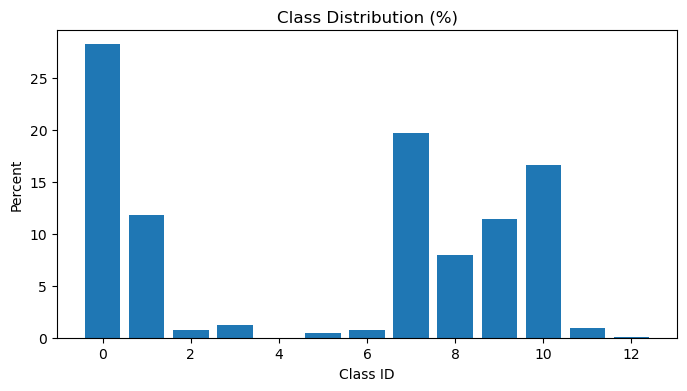

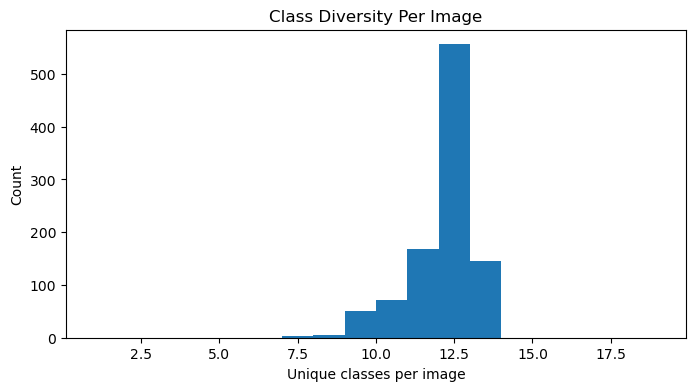

Average classes per image: 11.644

All label values found in dataset: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11), np.uint8(12)]
Normalized class weights: [0.15346289 0.31353979 1.47816515 1.28651823 2.04087346 1.64807507
 1.49765165 0.20672385 0.42648756 0.3209941  0.2369507  1.42174773
 1.96880983]


In [3]:
import os
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageFilter

# ------------------------------------
# 라벨을 제대로 읽기 위한 함수
# ------------------------------------
def load_label(path):
    raw = np.array(Image.open(path))
    if raw.ndim == 3:
        raw = raw[:, :, 0]  # RGB PNG에서 첫 채널만 사용 (class ID)
    return raw

# -------------------------------
# Convert mask → color image
# -------------------------------
def colorize_mask(mask):
    palette = np.array([
        [0, 0, 0],          # 0 None
        [70, 70, 70],       # 1 Buildings
        [190, 153, 153],    # 2 Fences
        [150, 120, 90],     # 3 Other
        [220, 20, 60],      # 4 Pedestrians
        [153, 153, 153],    # 5 Poles
        [255, 255, 0],      # 6 RoadLines
        [128, 64, 128],     # 7 Roads
        [244, 35, 232],     # 8 Sidewalks
        [107, 142, 35],     # 9 Vegetation
        [0, 0, 142],        # 10 Vehicles
        [102, 102, 156],    # 11 Walls
        [220, 220, 0],      # 12 TrafficSigns
    ], dtype=np.uint8)
    
    return palette[mask]


# ------------------------------------
# EDA 함수
# ------------------------------------
def run_full_eda(rgb_dir, label_dir):
    rgb_paths = sorted(glob.glob(os.path.join(rgb_dir, "*.png")))
    label_paths = sorted(glob.glob(os.path.join(label_dir, "*.png")))

    # --- 1: 파일 수 체크 ---
    print("RGB images:", len(rgb_paths))
    print("Label images:", len(label_paths))

    # --- 2: 해상도 분석 ---
    sizes = []
    for p in rgb_paths[:]:
        img = Image.open(p)
        sizes.append(img.size)
    print("\nUnique image sizes:", set(sizes))

    # --- 3: 클래스 비율 분석 ---
    class_counts = {i: 0 for i in range(13)}  # 클래스 ID 0~12

    for lp in tqdm(label_paths, desc="Class count"):
        mask = load_label(lp)
        unique, cnt = np.unique(mask, return_counts=True)
        for u, c in zip(unique, cnt):
            class_counts[u] += c

    total_pixels = sum(class_counts.values())
    class_ratio = {k: v / total_pixels * 100 for k, v in class_counts.items()}

    print("\nClass pixel ratio (%):")
    for k, v in class_ratio.items():
        print(f"Class {k}: {v:.3f}%")

    # 🔹 (선택) 클래스 가중치 계산: 자주 나오는 클래스는 가중치를 낮게, 희귀 클래스는 높게
    ratios = np.array([class_ratio[k] for k in sorted(class_ratio.keys())]) / 100.0
    # 1/log(1.02 + p) 형태 같은 간단한 스킴
    class_weights = 1.0 / np.log(1.02 + ratios)
    print("\nSuggested class weights:", class_weights)

    # 클래스 분포 그래프
    plt.figure(figsize=(8,4))
    plt.bar(class_ratio.keys(), class_ratio.values())
    plt.title("Class Distribution (%)")
    plt.xlabel("Class ID")
    plt.ylabel("Percent")
    plt.show()

    # --- 4: 이미지별 클래스 다양성 ---
    diversity = []
    for lp in label_paths:
        mask = load_label(lp)
        diversity.append(len(np.unique(mask)))

    plt.figure(figsize=(8,4))
    plt.hist(diversity, bins=range(1, 20))
    plt.title("Class Diversity Per Image")
    plt.xlabel("Unique classes per image")
    plt.ylabel("Count")
    plt.show()

    print("Average classes per image:", np.mean(diversity))

    # --- 5: 라벨 값 범위 검사 ---
    all_values = set()
    for lp in label_paths:
        mask = load_label(lp)
        all_values.update(np.unique(mask))

    print("\nAll label values found in dataset:", sorted(list(all_values)))

    return class_weights


# ------------------------------------
# 실행
# ------------------------------------
class_weights_np = run_full_eda("Training/RGB", "Training/Label")

# 🔹 클래스 가중치 정규화 (평균이 1이 되도록)
class_weights_np = class_weights_np / class_weights_np.mean()
print("Normalized class weights:", class_weights_np)

In [4]:
import glob, os
import numpy as np

label_paths = sorted(glob.glob(os.path.join("Training/Label", "*.png")))
num_images = len(label_paths)
num_classes = 13

image_count_per_class = {k: 0 for k in range(num_classes)}

for lp in label_paths:
    mask = load_label(lp)  
    uniq = np.unique(mask)
    for u in uniq:
        if u in image_count_per_class:
            image_count_per_class[u] += 1

print(f"total images: {num_images}")
for k in range(num_classes):
    print(f"class {k}: appears in {image_count_per_class[k]} images "
          f"({image_count_per_class[k]/num_images*100:.1f}%)")


total images: 1000
class 0: appears in 1000 images (100.0%)
class 1: appears in 900 images (90.0%)
class 2: appears in 994 images (99.4%)
class 3: appears in 884 images (88.4%)
class 4: appears in 180 images (18.0%)
class 5: appears in 991 images (99.1%)
class 6: appears in 972 images (97.2%)
class 7: appears in 1000 images (100.0%)
class 8: appears in 1000 images (100.0%)
class 9: appears in 1000 images (100.0%)
class 10: appears in 1000 images (100.0%)
class 11: appears in 777 images (77.7%)
class 12: appears in 946 images (94.6%)


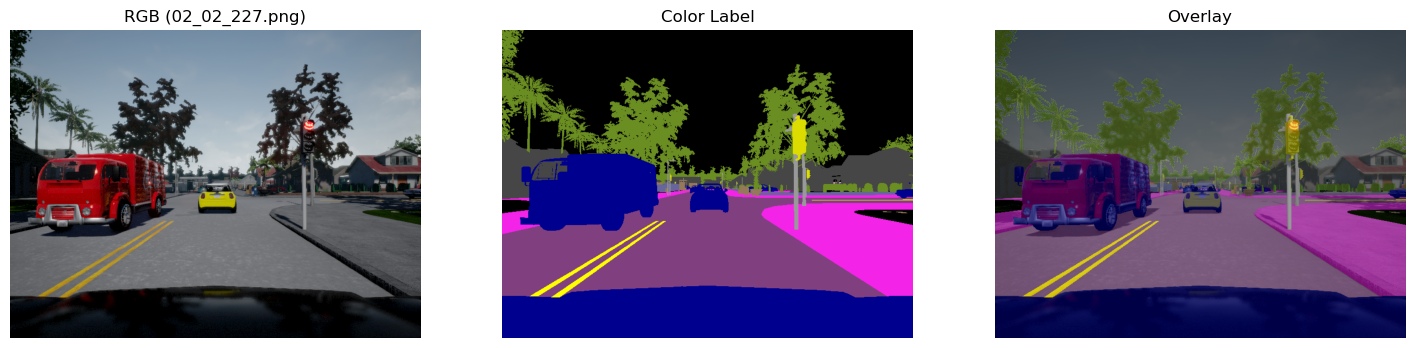

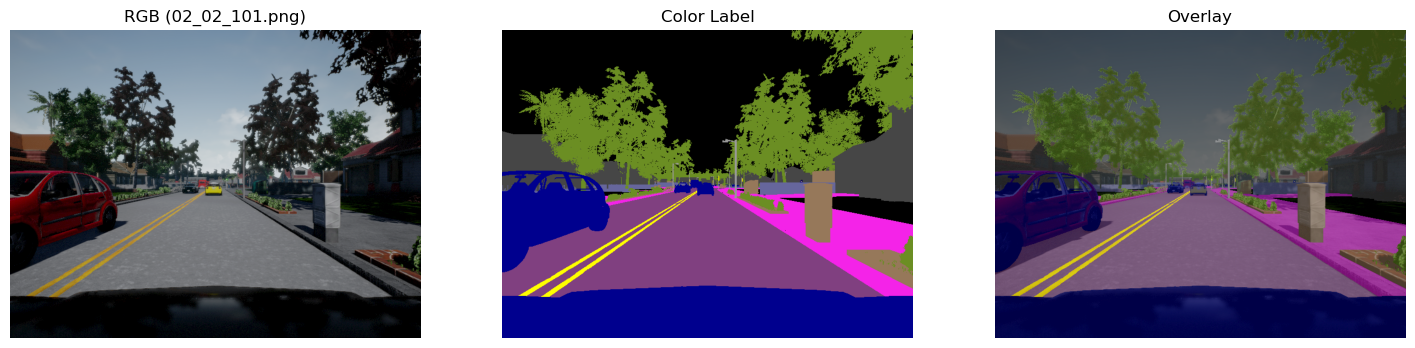

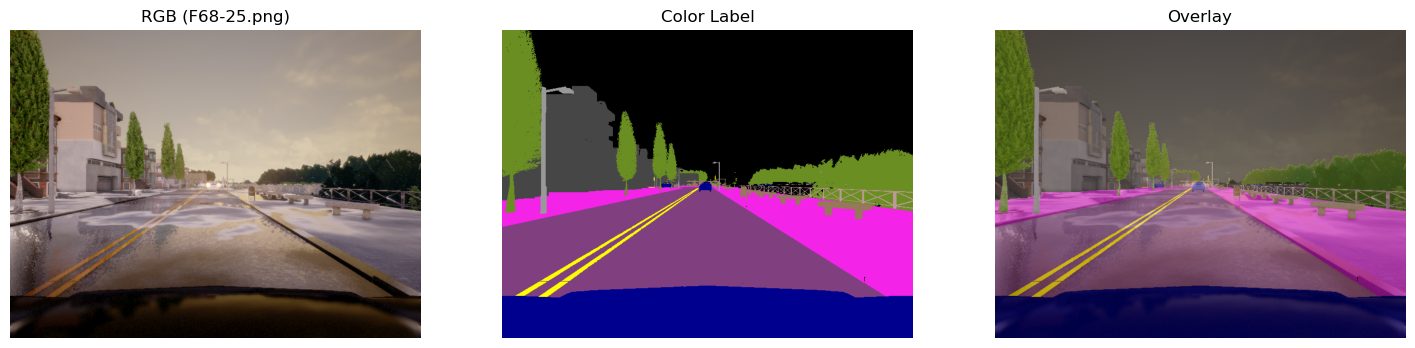

In [5]:
import random

def visualize_random_samples(rgb_dir, label_dir, N=5, alpha=0.5):
    rgb_files = sorted(os.listdir(rgb_dir))
    label_files = sorted(os.listdir(label_dir))

    # 파일명 개수 체크
    if len(rgb_files) != len(label_files):
        print("⚠️ Warning: RGB와 Label 개수가 다릅니다!")
    
    # N개의 랜덤 sample 선택
    indices = random.sample(range(len(rgb_files)), N)

    for idx in indices:
        rgb_path = os.path.join(rgb_dir, rgb_files[idx])
        label_path = os.path.join(label_dir, label_files[idx])

        # Load data
        rgb = np.array(Image.open(rgb_path).convert("RGB"))
        label = load_label(label_path)
        color_label = colorize_mask(label)

        # Overlay 생성
        overlay = (rgb * (1 - alpha) + color_label * alpha).astype(np.uint8)

        # Plot
        plt.figure(figsize=(18,6))

        plt.subplot(1,3,1)
        plt.title(f"RGB ({rgb_files[idx]})")
        plt.imshow(rgb)
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.title("Color Label")
        plt.imshow(color_label)
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.title("Overlay")
        plt.imshow(overlay)
        plt.axis("off")

        plt.show()

visualize_random_samples("Training/RGB", "Training/Label", N=3)


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

NUM_CLASSES = 13

# ResNet Bottleneck 블록만 별도 정의 (이건 그냥 최소 단위라고 생각하자)
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_channels, mid_channels,
                 stride=1, dilation=1, downsample=None):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, mid_channels,
                               kernel_size=1, stride=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)

        self.conv2 = nn.Conv2d(
            mid_channels,
            mid_channels,
            kernel_size=3,
            stride=stride,
            padding=dilation,
            dilation=dilation,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(mid_channels)

        self.conv3 = nn.Conv2d(mid_channels,
                               mid_channels * self.expansion,
                               kernel_size=1, stride=1, bias=False)
        self.bn3 = nn.BatchNorm2d(mid_channels * self.expansion)

        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class MyFcnResNet50(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # --------- conv1 부분 ---------
        self.conv1 = nn.Conv2d(3, 64,
                               kernel_size=7,
                               stride=2,
                               padding=3,
                               bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3,
                                    stride=2,
                                    padding=1)

        # --------- ResNet layer1~4 (FCN_ResNet50 스타일) ---------
        # layer1: in=64, mid=64, blocks=3, stride=1, dilation=1
        self.layer1 = self._make_layer(
            in_channels=64,
            mid_channels=64,
            blocks=3,
            stride=1,
            dilations=[1, 1, 1]
        )

        # layer2: in=256, mid=128, blocks=4, 첫 블록 stride=2
        self.layer2 = self._make_layer(
            in_channels=256,
            mid_channels=128,
            blocks=4,
            stride=2,
            dilations=[1, 1, 1, 1]
        )

        # layer3: in=512, mid=256, blocks=6
        #   block0: dilation=1
        #   block1~5: dilation=2
        self.layer3 = self._make_layer(
            in_channels=512,
            mid_channels=256,
            blocks=6,
            stride=1,
            dilations=[1, 2, 2, 2, 2, 2]
        )

        # layer4: in=1024, mid=512, blocks=3
        #   block0: dilation=2
        #   block1,2: dilation=4
        self.layer4 = self._make_layer(
            in_channels=1024,
            mid_channels=512,
            blocks=3,
            stride=1,
            dilations=[2, 4, 4]
        )

        # --------- FCNHead와 동일한 classifier / aux_classifier ---------
        # main classifier: layer4(2048ch) → 512 → num_classes
        self.classifier = nn.Sequential(
            nn.Conv2d(2048, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(512, num_classes, kernel_size=1)
        )

        # aux classifier: layer3(1024ch) → 256 → num_classes
        self.aux_classifier = nn.Sequential(
            nn.Conv2d(1024, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(256, num_classes, kernel_size=1)
        )

    # layer1~4 만드는 헬퍼 (클래스 안에 포함)
    def _make_layer(self, in_channels, mid_channels,
                    blocks, stride, dilations):
        assert len(dilations) == blocks

        layers = []

        first_dilation = dilations[0]
        out_channels = mid_channels * Bottleneck.expansion

        downsample = None
        if stride != 1 or in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1,
                          stride=stride,
                          bias=False),
                nn.BatchNorm2d(out_channels),
            )

        # 첫 블록
        layers.append(
            Bottleneck(
                in_channels=in_channels,
                mid_channels=mid_channels,
                stride=stride,
                dilation=first_dilation,
                downsample=downsample
            )
        )

        # 나머지 블록들
        in_channels = out_channels
        for d in dilations[1:]:
            layers.append(
                Bottleneck(
                    in_channels=in_channels,
                    mid_channels=mid_channels,
                    stride=1,
                    dilation=d,
                    downsample=None
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        H, W = x.shape[2], x.shape[3]

        # backbone
        x = self.conv1(x)    # H/2
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)  # H/4

        x1 = self.layer1(x)   # (B, 256, H/4, W/4)
        x2 = self.layer2(x1)  # (B, 512, H/8, W/8)
        x3 = self.layer3(x2)  # (B, 1024, H/8, W/8)
        x4 = self.layer4(x3)  # (B, 2048, H/8, W/8)

        # main head
        main = self.classifier(x4)  # (B, C, H/8, W/8)
        main = F.interpolate(main, size=(H, W),
                             mode="bilinear", align_corners=False)

        # aux head
        aux = self.aux_classifier(x3)  # (B, C, H/8, W/8)
        aux = F.interpolate(aux, size=(H, W),
                            mode="bilinear", align_corners=False)

        return {"out": main, "aux": aux}
        # 그냥 main만 쓰고 싶으면 return main 해도 됨

In [7]:
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import torch
import os
import random

class SegDataset(Dataset):
    def __init__(self, rgb_dir, label_dir, train=True, transform=None):
        self.rgb_dir = rgb_dir
        self.label_dir = label_dir        
        self.train = train
        self.transform = transform

        self.rgb_files = sorted(os.listdir(rgb_dir))
        self.label_files = sorted(os.listdir(label_dir))

        assert len(self.rgb_files) == len(self.label_files), "RGB/Label 개수 불일치"

        # 🔹 희귀 클래스 정의 (예시: 보행자, 차선, 표지판)
        self.rare_classes = {4, 6, 12}

        # 🔹 각 이미지에 희귀 클래스가 포함되어 있는지 미리 계산
        self.has_rare = []
        if self.train:
            print(">> 스캔 중: 희귀 클래스 포함 이미지 체크...")
            for lf in tqdm(self.label_files):
                label_path = os.path.join(self.label_dir, lf)
                mask = load_label(label_path)  # 위에 정의한 load_label 재사용
                present = np.isin(mask, list(self.rare_classes)).any()
                self.has_rare.append(present)
        else:
            # val/test는 augmentation 안 쓰니까 그냥 False로 채워둬도 됨
            self.has_rare = [False] * len(self.label_files)


    def __len__(self):
        return len(self.rgb_files)

    def __getitem__(self, idx):
        # 파일 경로
        rgb_path = os.path.join(self.rgb_dir, self.rgb_files[idx])
        label_path = os.path.join(self.label_dir, self.label_files[idx])

        # RGB / Label 로드
        rgb = Image.open(rgb_path).convert("RGB")
        label_raw = np.array(Image.open(label_path))
        
        # 라벨이 3채널이면 첫 채널 사용
        if label_raw.ndim == 3:
            label = label_raw[:, :, 0]
        else:
            label = label_raw

        # ---------- 데이터 증강: train일 때만 ----------
        if self.train:
            # 이 이미지에 희귀 클래스가 포함되어 있는지
            is_rare_img = self.has_rare[idx]

            # 희귀 이미지면 augmentation을 더 자주/강하게 적용
            # 예: 희귀 이미지 → 1.0, 일반 이미지 → 0.4
            aug_factor = 1.0 if is_rare_img else 0.4

            # (1) 랜덤 좌우 플립
            if random.random() < 0.5 * aug_factor:
                rgb = TF.hflip(rgb)
                label = np.fliplr(label).copy()

            # (2) color jitter (살짝 줄임)
            if random.random() < 0.3 * aug_factor:
                factor_b = 0.7 + 0.6 * random.random()
                factor_c = 0.7 + 0.6 * random.random()
                rgb = TF.adjust_brightness(rgb, factor_b)
                rgb = TF.adjust_contrast(rgb, factor_c)

            # (3) 가우시안 블러는 희귀 이미지일 때만 조금
            if is_rare_img and random.random() < 0.15 * aug_factor:
                rgb = rgb.filter(ImageFilter.GaussianBlur(radius=1.5))

            # (4) 랜덤 크롭 (예: 512x512)
            h, w = label.shape
            crop_h, crop_w = 512, 512
            if h >= crop_h and w >= crop_w:
                top = random.randint(0, h - crop_h)
                left = random.randint(0, w - crop_w)
                rgb = TF.crop(rgb, top, left, crop_h, crop_w)
                label = label[top:top+crop_h, left:left+crop_w]


        # To Tensor
        rgb = TF.to_tensor(rgb)                        # → (3,H,W), float32, [0,1]
        label = torch.tensor(label, dtype=torch.long)  # → (H,W), long

        return rgb, label


In [8]:
from torch.utils.data import DataLoader

train_dataset = SegDataset("Training/RGB", "Training/Label")

>> 스캔 중: 희귀 클래스 포함 이미지 체크...


100%|██████████| 1000/1000 [00:03<00:00, 269.32it/s]


In [9]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [10]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


In [24]:
import torch
import torch.nn.functional as F
import numpy as np

def train_seg(model, data_loader, optimizer, device, class_weights=None):
    model.train()
    trn_loss = 0.0
    total_pixels = 0
    correct_pixels = 0

    for i, (x, y) in enumerate(data_loader):
        x = x.to(device)           # (B, 3, H, W)
        y = y.to(device)           # (B, H, W)

        optimizer.zero_grad()

        # forward
        out_dict = model(x)
        main_logits = out_dict["out"]          # (B, C, H, W)
        aux_logits  = out_dict["aux"]          # (B, C, H, W)

        if class_weights is not None:
            main_loss = F.cross_entropy(main_logits, y,
                                        weight=class_weights,
                                        reduction='mean')
            aux_loss  = F.cross_entropy(aux_logits,  y,
                                        weight=class_weights,
                                        reduction='mean')
        else:
            main_loss = F.cross_entropy(main_logits, y, reduction='mean')
            aux_loss  = F.cross_entropy(aux_logits,  y, reduction='mean')

        loss = main_loss + 0.4 * aux_loss

        loss.backward()
        optimizer.step()

        trn_loss += loss.item()

        # pixel accuracy 계산
        with torch.no_grad():
            preds = main_logits.argmax(dim=1)  # (B, H, W)
            correct = (preds == y).sum().item()
            pixels  = y.numel()
            correct_pixels += correct
            total_pixels   += pixels

    # 🔹 loss 평균은 "step 수" 기준으로 나누는 게 자연스러움
    avg_trn_loss = trn_loss / len(data_loader)
    trn_acc = correct_pixels / total_pixels
    return avg_trn_loss, trn_acc


def evaluate_seg(model, data_loader, device, class_weights=None, num_classes=NUM_CLASSES):
    """
    한 epoch 동안 val set에 대해:
      - 평균 loss
      - pixel accuracy
      - mIoU
    를 함께 반환
    """
    model.eval()
    eval_loss = 0.0
    total_pixels = 0
    correct_pixels = 0

    # IoU 계산을 위한 confusion matrix
    conf_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)

    with torch.no_grad():
        for i, (x, y) in enumerate(data_loader):
            x = x.to(device)
            y = y.to(device)

            out_dict = model(x)
            main_logits = out_dict["out"]
            aux_logits  = out_dict["aux"]

            if class_weights is not None:
                main_loss = F.cross_entropy(main_logits, y,
                                            weight=class_weights,
                                            reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits,  y,
                                            weight=class_weights,
                                            reduction='mean')
            else:
                main_loss = F.cross_entropy(main_logits, y, reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits,  y, reduction='mean')

            loss = main_loss + 0.4 * aux_loss

            eval_loss += loss.item()

            preds = main_logits.argmax(dim=1)  # (B,H,W)
            correct = (preds == y).sum().item()
            pixels  = y.numel()
            correct_pixels += correct
            total_pixels   += pixels

            # IoU 계산을 위해 confusion matrix 업데이트
            preds_flat = preds.view(-1).cpu().numpy()
            y_flat     = y.view(-1).cpu().numpy()

            for t, p in zip(y_flat, preds_flat):
                if 0 <= t < num_classes:
                    conf_matrix[t, p] += 1

            # # GPU 텐서로 confusion matrix 업데이트
            # k = num_classes
            # indices = y * k + preds   # maps (t,p) -> unique index
            # conf_matrix += torch.bincount(indices.flatten(),
            #                             minlength=k*k).reshape(k, k).cpu().numpy()

    avg_eval_loss = eval_loss / len(data_loader)
    eval_acc = correct_pixels / total_pixels

    # class별 IoU 및 mIoU 계산
    ious = []
    for cls in range(num_classes):
        tp = conf_matrix[cls, cls]
        fp = conf_matrix[:, cls].sum() - tp
        fn = conf_matrix[cls, :].sum() - tp

        denom = tp + fp + fn
        if denom == 0:
            iou = float("nan")
        else:
            iou = tp / denom
        ious.append(iou)

    valid_ious = [x for x in ious if not np.isnan(x)]
    miou = np.mean(valid_ious) if len(valid_ious) > 0 else 0.0

    return avg_eval_loss, eval_acc, miou


In [12]:
from torch.utils.data import DataLoader
from torch.utils.data import WeightedRandomSampler  # 🔹 추가

# 🔹 Training 폴더: 학습 전용
train_dataset = SegDataset("Training/RGB", "Training/Label", train=True)

# 🔹 Validation 폴더: 성능 확인/평가용 (val + test 역할)
val_dataset   = SegDataset("Validation/RGB", "Validation/Label", train=False)

print(f"train: {len(train_dataset)}, val: {len(val_dataset)}")

BATCH_SIZE = 4  # 메모리 보고 조절

# 🔹 rare-class oversampling을 위한 샘플 가중치 생성
#    SegDataset에서 미리 계산해 둔 train_dataset.has_rare 를 사용
sample_weights = []
for has_rare in train_dataset.has_rare:
    if has_rare:
        sample_weights.append(3.0)   # 희귀 클래스 포함 이미지 → 더 자주 뽑히게
    else:
        sample_weights.append(1.0)   # 나머지 → 기본

# 필요하면 비율 조정 가능 (예: 5.0 / 1.0 등)
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),  # 한 epoch에 평균적으로 전체를 한 번 도는 수준
    replacement=True                  # 복원 추출로 rare 이미지는 여러 번 뽑힐 수 있음
)

# 🔹 train_loader는 sampler 기반 (shuffle=False로 두거나 아예 안 넣음)
trn_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    drop_last=False,
)

# 🔹 val_loader는 그대로 (shuffle만 False 유지)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)

# 편의상 test_dataset / test_loader도 같은 걸로 두고 싶다면:
test_dataset = val_dataset
test_loader  = val_loader


>> 스캔 중: 희귀 클래스 포함 이미지 체크...


100%|██████████| 1000/1000 [00:03<00:00, 272.05it/s]

train: 1000, val: 1000


In [13]:
import torch
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MyFcnResNet50(num_classes=13).to(device)

LR = 2e-4
my_opt = optim.Adam(model.parameters(), lr=LR)

# ★ 여기 추가
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer=my_opt,
    mode='max',      # val_acc가 커질수록 좋음
    factor=0.5,      # LR = LR * 0.5
    patience=1,      # 1 epoch 동안 개선 없으면 줄임
)

class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)

In [14]:
def evaluate_seg_acc_only(model, data_loader, device, class_weights=None):
    model.eval()
    eval_loss = 0.0
    total_pixels = 0
    correct_pixels = 0

    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)
            y = y.to(device)

            out_dict = model(x)
            main_logits = out_dict["out"]
            aux_logits  = out_dict["aux"]

            # ★ evaluate_seg()와 동일한 loss 계산
            if class_weights is not None:
                main_loss = F.cross_entropy(main_logits, y,
                                            weight=class_weights,
                                            reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits, y,
                                            weight=class_weights,
                                            reduction='mean')
            else:
                main_loss = F.cross_entropy(main_logits, y, reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits, y, reduction='mean')

            loss = main_loss + 0.4 * aux_loss
            eval_loss += loss.item()

            # ★ pixel accuracy 동일
            preds = main_logits.argmax(dim=1)
            correct_pixels += (preds == y).sum().item()
            total_pixels   += y.numel()

    avg_loss = eval_loss / len(data_loader)
    pixel_acc = correct_pixels / total_pixels
    return avg_loss, pixel_acc


In [15]:
import time
import os

N_EPOCH = 20
best_val_acc = -1.0       # pixel accuracy는 클수록 좋음
tolerance = 0
MAX_TOL = 5
model_path = 'models_seg'

if not os.path.exists(model_path):
    os.makedirs(model_path)

# 학습 과정 기록용 리스트
history_trn_loss = []
history_trn_acc  = []
history_val_loss = []
history_val_acc  = []
history_val_miou = []

for epoch in range(N_EPOCH):
    start_time = time.time()

    trn_loss, trn_acc = train_seg(model=model,
                                  data_loader=trn_loader,
                                  optimizer=my_opt,
                                  device=device,
                                  class_weights=class_weights)

    val_loss, val_acc = evaluate_seg_acc_only(model=model,
                                               data_loader=val_loader,
                                               device=device,
                                               class_weights=class_weights #,
                                            #    num_classes=NUM_CLASSES)
                                            )
    
    scheduler.step(val_acc)


    end_time = time.time()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    # 기록 저장
    history_trn_loss.append(trn_loss)
    history_trn_acc.append(trn_acc)
    history_val_loss.append(val_loss)
    history_val_acc.append(val_acc)
    # history_val_miou.append(val_miou)

    print(f'Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s')
    print(f'\tTrn Loss: {trn_loss:.4f} | Trn Acc: {100*trn_acc:.2f}%')
    print(f'\tVal Loss: {val_loss:.4f} | Val Acc: {100*val_acc:.2f}% ')

    # 🔹 val_acc 기준으로 best 모델 저장
    if val_acc > best_val_acc:
        print(f'\tval_acc({val_acc:.4f}) > best_val_acc({best_val_acc:.4f}) → 모델 저장')
        best_val_acc = val_acc
        tolerance = 0
        torch.save(model.state_dict(), f'{model_path}/myFcnResNet50_Scheduler.pt')
    else:
        tolerance += 1
        print(f'\tval_acc({val_acc:.4f}) <= best_val_acc({best_val_acc:.4f}) → tolerance={tolerance}')

    # 🔹 Early stopping도 accuracy 기준
    if tolerance >= MAX_TOL:
        print(f'>> tolerance={tolerance}. Stop training!\n')
        break



Epoch: 01 | Time: 1m 51s
	Trn Loss: 1.3324 | Trn Acc: 78.33%
	Val Loss: 1.7617 | Val Acc: 77.42% 
	val_acc(0.7742) > best_val_acc(-1.0000) → 모델 저장
Epoch: 02 | Time: 1m 44s
	Trn Loss: 0.7177 | Trn Acc: 88.00%
	Val Loss: 1.9091 | Val Acc: 78.93% 
	val_acc(0.7893) > best_val_acc(0.7742) → 모델 저장
Epoch: 03 | Time: 1m 43s
	Trn Loss: 0.5362 | Trn Acc: 90.80%
	Val Loss: 1.7538 | Val Acc: 71.09% 
	val_acc(0.7109) <= best_val_acc(0.7893) → tolerance=1
Epoch: 04 | Time: 1m 43s
	Trn Loss: 0.4724 | Trn Acc: 91.60%
	Val Loss: 1.4714 | Val Acc: 83.56% 
	val_acc(0.8356) > best_val_acc(0.7893) → 모델 저장
Epoch: 05 | Time: 1m 43s
	Trn Loss: 0.4044 | Trn Acc: 92.64%
	Val Loss: 1.7173 | Val Acc: 74.74% 
	val_acc(0.7474) <= best_val_acc(0.8356) → tolerance=1
Epoch: 06 | Time: 1m 52s
	Trn Loss: 0.3320 | Trn Acc: 93.59%
	Val Loss: 1.4266 | Val Acc: 83.85% 
	val_acc(0.8385) > best_val_acc(0.8356) → 모델 저장
Epoch: 07 | Time: 1m 43s
	Trn Loss: 0.3404 | Trn Acc: 93.49%
	Val Loss: 1.6090 | Val Acc: 83.64% 
	val_acc(0.

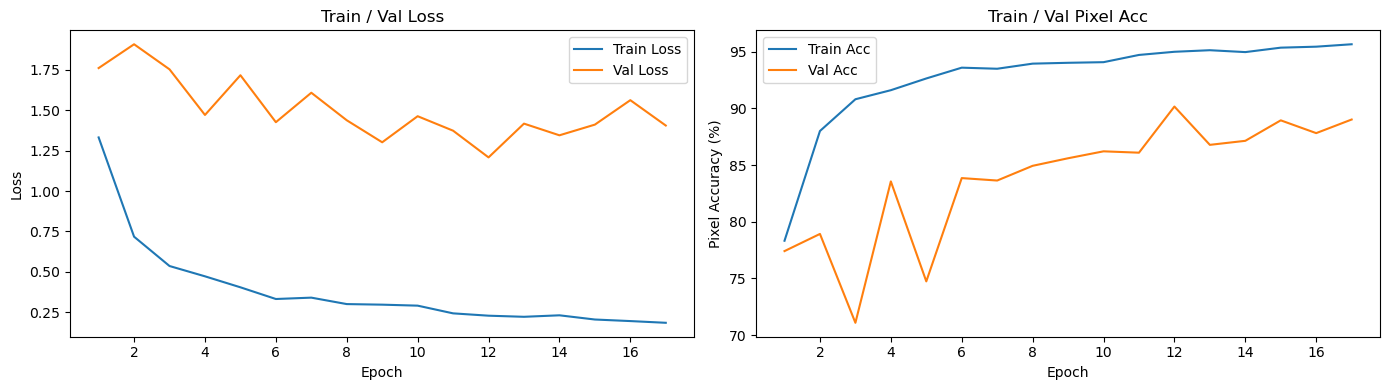

In [16]:
# 학습/검증 곡선 시각화 (loss, pixel acc, mIoU)

epochs_range = range(1, len(history_trn_loss) + 1)

plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
plt.plot(epochs_range, history_trn_loss, label="Train Loss")
plt.plot(epochs_range, history_val_loss, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train / Val Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs_range, [a*100 for a in history_trn_acc], label="Train Acc")
plt.plot(epochs_range, [a*100 for a in history_val_acc], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Pixel Accuracy (%)")
plt.title("Train / Val Pixel Acc")
plt.legend()

# plt.subplot(1,3,3)
# plt.plot(epochs_range, [m*100 for m in history_val_miou], label="Val mIoU")
# plt.xlabel("Epoch")
# plt.ylabel("mIoU (%)")
# plt.title("Validation mIoU")
# plt.legend()

plt.tight_layout()
plt.show()


In [25]:
import numpy as np
import torch

def evaluate_model(model, dataloader, num_classes=NUM_CLASSES, device="cuda"):
    model.eval()
    model.to(device)

    conf_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    total_correct = 0
    total_pixels = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks  = masks.to(device)  # (B,H,W)

            # ★ 네 모델은 dict로 반환하므로 이렇게 받아야 함
            out_dict = model(images)
            outputs = out_dict["out"]     # (B,C,H,W)

            preds = torch.argmax(outputs, dim=1)  # (B,H,W)

            # Pixel Accuracy
            total_correct += (preds == masks).sum().item()
            total_pixels  += masks.numel()

            # Confusion Matrix 업데이트
            preds_flat = preds.view(-1).cpu().numpy()
            masks_flat = masks.view(-1).cpu().numpy()

            for t, p in zip(masks_flat, preds_flat):
                if t < num_classes:
                    conf_matrix[t, p] += 1

    # Pixel Accuracy
    pixel_acc = total_correct / total_pixels

    # IoU per class
    ious = []
    for cls in range(num_classes):
        tp = conf_matrix[cls, cls]
        fp = conf_matrix[:, cls].sum() - tp
        fn = conf_matrix[cls, :].sum() - tp

        denom = tp + fp + fn
        if denom == 0:
            iou = float("nan")
        else:
            iou = tp / denom

        ious.append(iou)

    # mIoU
    valid_ious = [x for x in ious if not np.isnan(x)]
    miou = np.mean(valid_ious) if len(valid_ious) > 0 else 0.0

    return pixel_acc, ious, miou, conf_matrix


In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

best_model_path = f'{model_path}/myFcnResNet50_Scheduler.pt'
model.load_state_dict(torch.load(best_model_path, map_location=device))

pixel_acc, ious, miou, confmat = evaluate_model(model, val_loader, NUM_CLASSES, device)


print(f"Pixel Accuracy: {pixel_acc*100:.2f}%")
print(f"mIoU: {miou*100:.2f}%")

class_names = [
    "None",
    "Buildings",
    "Fences",
    "Other",
    "Pedestrians",
    "Poles",
    "RoadLines",
    "Roads",
    "Sidewalks",
    "Vegetation",
    "Vehicles",
    "Walls",
    "TrafficSigns",
]

for i, iou in enumerate(ious):
    if np.isnan(iou):
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = N/A (not present)")
    else:
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = {iou*100:5.2f}%")


Pixel Accuracy: 90.16%
mIoU: 53.61%
Class  0 (None        ): IoU = 92.74%
Class  1 (Buildings   ): IoU = 71.04%
Class  2 (Fences      ): IoU = 19.00%
Class  3 (Other       ): IoU = 19.20%
Class  4 (Pedestrians ): IoU =  0.00%
Class  5 (Poles       ): IoU = 31.11%
Class  6 (RoadLines   ): IoU = 54.84%
Class  7 (Roads       ): IoU = 88.46%
Class  8 (Sidewalks   ): IoU = 70.41%
Class  9 (Vegetation  ): IoU = 73.11%
Class 10 (Vehicles    ): IoU = 94.96%
Class 11 (Walls       ): IoU = 29.58%
Class 12 (TrafficSigns): IoU = 52.45%


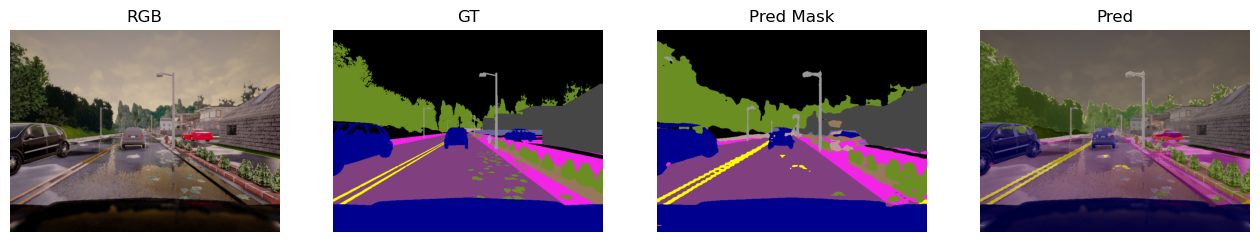

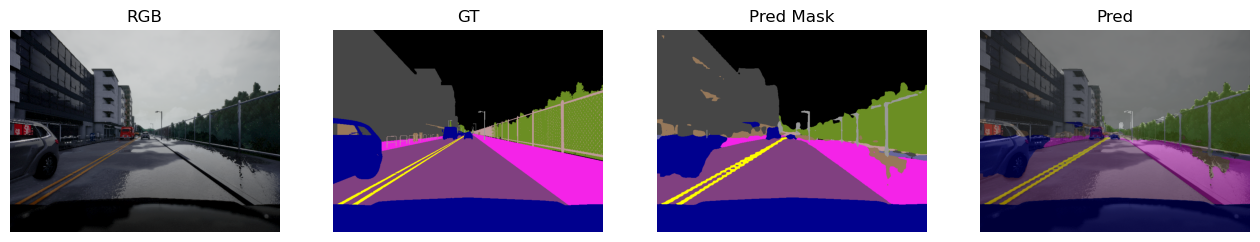

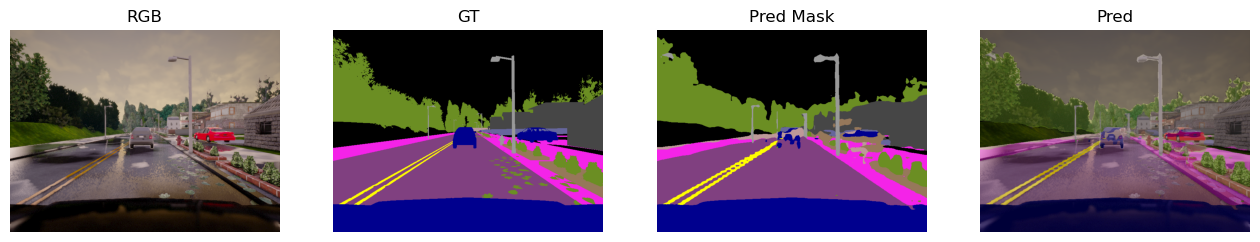

In [27]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def visualize_val_samples(model, dataset, indices, device="cuda"):
    # device 문자열/torch.device 둘 다 허용
    if isinstance(device, str):
        device = torch.device(device)

    model.eval()
    model.to(device)

    for idx in indices:
        # dataset은 SegDataset 또는 random_split으로 나온 Subset
        rgb, gt = dataset[idx]          # rgb: (3,H,W), gt: (H,W)
        img = rgb.unsqueeze(0).to(device)  # (1,3,H,W)

        with torch.no_grad():
            out_dict = model(img)       # dict: {"out": main, "aux": aux}
            logits = out_dict["out"]    # (1,C,H,W)
            pred = torch.argmax(logits, dim=1)[0].cpu().numpy()  # (H,W)

        gt_np = gt.numpy()                                # (H,W)
        rgb_np = (rgb.numpy().transpose(1, 2, 0) * 255).astype(np.uint8)  # (H,W,3)

        # 🔴 여기서 colorize_mask 사용 (네가 위에서 정의한 함수)
        gt_color = colorize_mask(gt_np)      # (H,W,3)
        pred_color = colorize_mask(pred)     # (H,W,3)

        # overlay_gt   = (0.6*rgb_np + 0.4*gt_color).astype(np.uint8)
        overlay_pred = (0.6*rgb_np + 0.4*pred_color).astype(np.uint8)

        plt.figure(figsize=(16,6))
        plt.subplot(1,4,1); plt.title("RGB");       plt.imshow(rgb_np);      plt.axis("off")
        plt.subplot(1,4,2); plt.title("GT");        plt.imshow(gt_color);  plt.axis("off")
        plt.subplot(1,4,3); plt.title("Pred Mask"); plt.imshow(pred_color);plt.axis("off")
        plt.subplot(1,4,4); plt.title("Pred");      plt.imshow(overlay_pred);  plt.axis("off")
        plt.show()

best_model_path = f'{model_path}/myFcnResNet50_Scheduler.pt'
model.load_state_dict(torch.load(best_model_path, map_location=device))

num_samples = 3
rand_indices = random.sample(range(len(test_dataset)), num_samples)

visualize_val_samples(model, test_dataset, indices=rand_indices, device=device)


In [28]:
from torch.utils.data import DataLoader

def get_best_worst_middle_indices(model, dataset, device="cuda", num_classes=NUM_CLASSES):
    """
    각 이미지별 pixel accuracy를 계산해서
    - best 3
    - worst 3
    - middle 3
    의 dataset 인덱스를 반환
    """
    if isinstance(device, str):
        device = torch.device(device)

    model.eval()
    model.to(device)

    scores = []  # (idx, acc) 저장

    # shuffle=False 로 해야 DataLoader 순서 = dataset 인덱스 순서
    loader = DataLoader(dataset,
                        batch_size=1,
                        shuffle=False)

    with torch.no_grad():
        for idx, (rgb, gt) in enumerate(loader):
            rgb = rgb.to(device)      # (1,3,H,W)
            gt  = gt.to(device)       # (1,H,W)

            out_dict = model(rgb)
            logits = out_dict["out"]  # (1,C,H,W)
            pred = torch.argmax(logits, dim=1)  # (1,H,W)

            correct = (pred == gt).sum().item()
            total   = gt.numel()
            acc = correct / total

            scores.append((idx, acc))

    # accuracy 기준으로 오름차순 정렬 (제일 못한 게 앞에)
    scores.sort(key=lambda x: x[1])

    n = len(scores)

    # worst 3 (accuracy 제일 낮은 것들)
    worst_indices = [idx for idx, _ in scores[:3]]

    # best 3 (accuracy 제일 높은 것들)
    best_indices = [idx for idx, _ in scores[-3:]][::-1]  # 내림차순 느낌 나게 뒤집기

    # middle 3 (정 가운데 근처 3개)
    mid_start = max(0, n // 2 - 1)
    middle_indices = [idx for idx, _ in scores[mid_start:mid_start+3]]

    # print("Worst indices :", worst_indices)
    # print("Middle indices:", middle_indices)
    # print("Best indices  :", best_indices)

    return best_indices, worst_indices, middle_indices, scores


# 먼저 index 뽑기
best_idx, worst_idx, mid_idx, scores = get_best_worst_middle_indices(
    model,
    test_dataset,
    device=device,
    num_classes=NUM_CLASSES
)


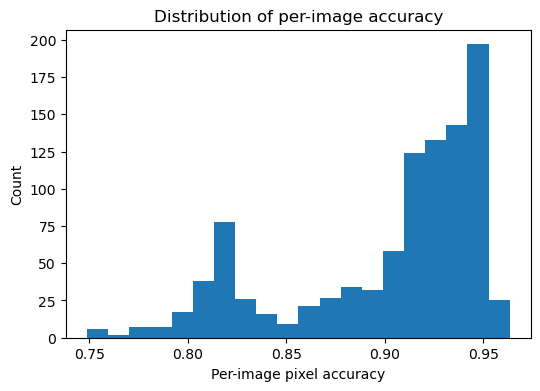

In [21]:
import matplotlib.pyplot as plt

# scores: [(idx, acc), (idx, acc), ...]
indices = [s[0] for s in scores]
accs    = [s[1] for s in scores]

plt.figure(figsize=(6,4))
plt.hist(accs, bins=20)
plt.xlabel("Per-image pixel accuracy")
plt.ylabel("Count")
plt.title("Distribution of per-image accuracy")
plt.show()


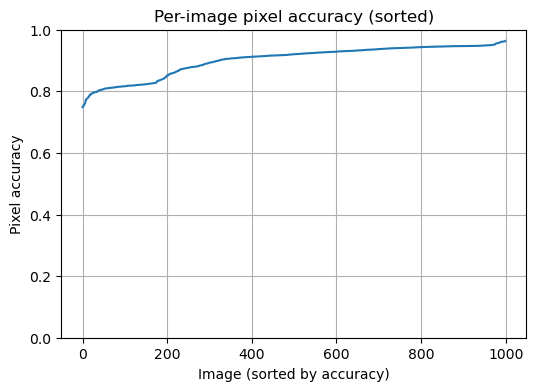

In [29]:
# scores가 accuracy 기준으로 정렬된 상태니까,
# 원래 순서로 보고 싶으면 다시 정렬해도 되고,
# 그냥 "정확도 오름차순 곡선"으로 봐도 재밌음.

sorted_accs = [s[1] for s in scores]  # 오름차순 정렬된 accuracy

plt.figure(figsize=(6,4))
plt.plot(sorted_accs)
plt.xlabel("Image (sorted by accuracy)")
plt.ylabel("Pixel accuracy")
plt.title("Per-image pixel accuracy (sorted)")
plt.ylim(0, 1.0)
plt.grid(True)
plt.show()



=== Best 3 samples ===
Index 806, accuracy=96.35%
Index 817, accuracy=96.22%
Index 811, accuracy=96.21%


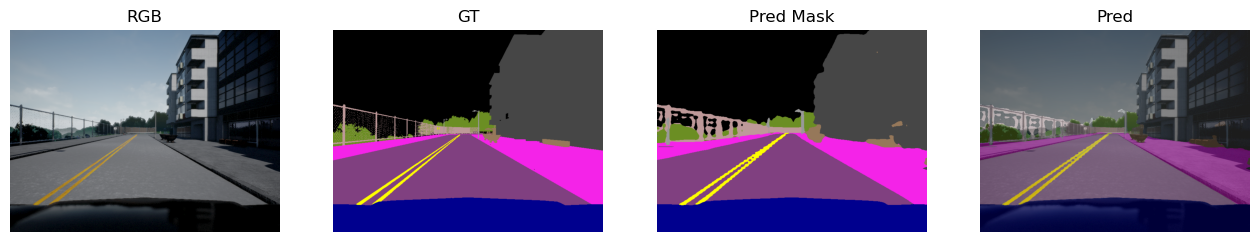

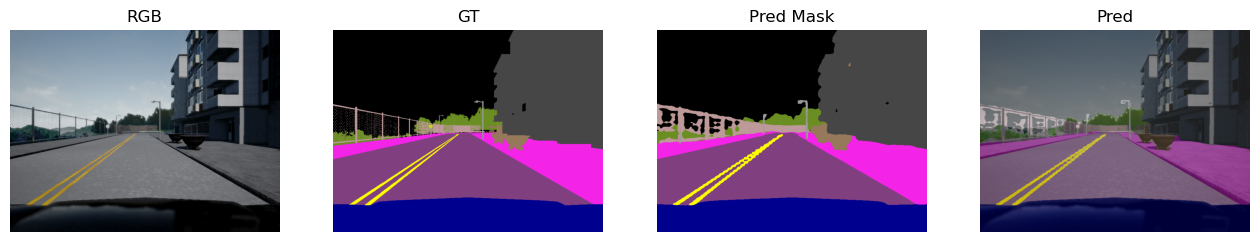

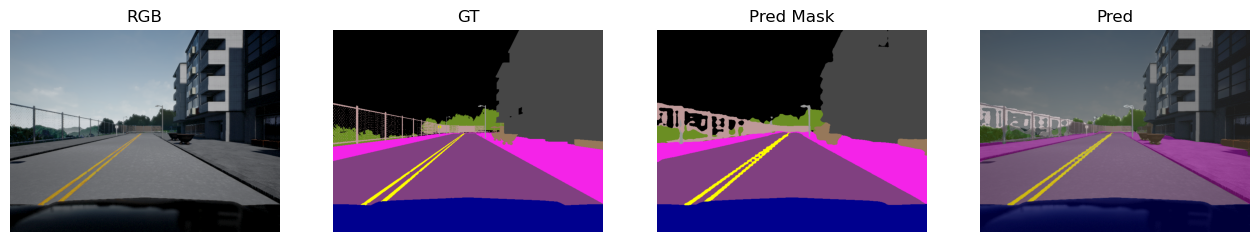


=== Worst 3 samples ===
Index 761, accuracy=74.88%
Index 759, accuracy=75.08%
Index 760, accuracy=75.10%


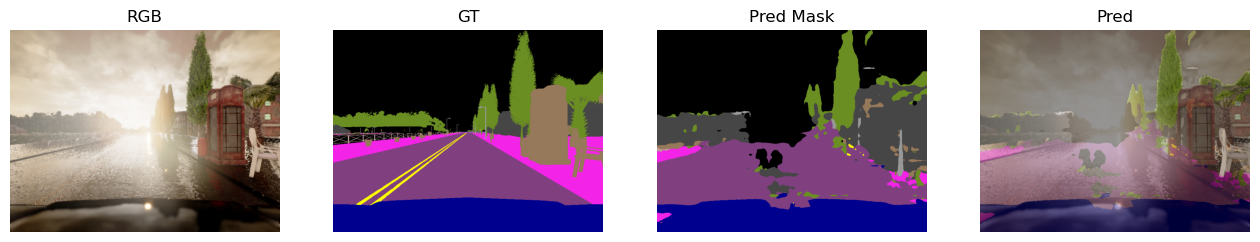

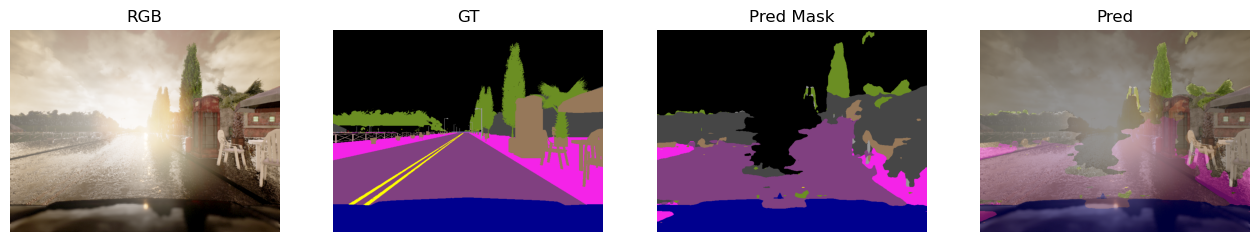

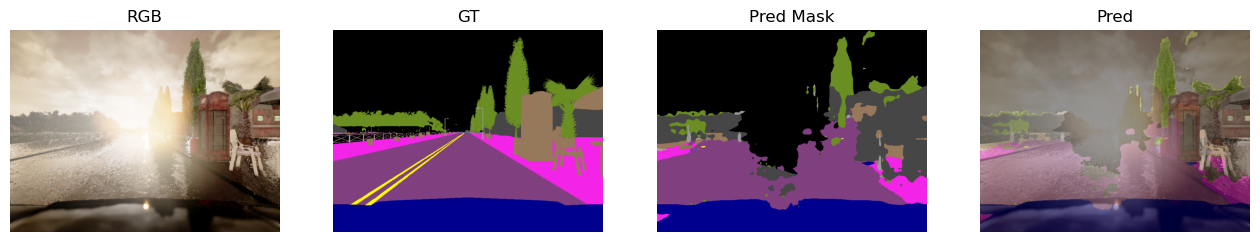


=== Middle 3 samples ===
Index 106, accuracy=92.03%
Index 486, accuracy=92.03%
Index 472, accuracy=92.04%


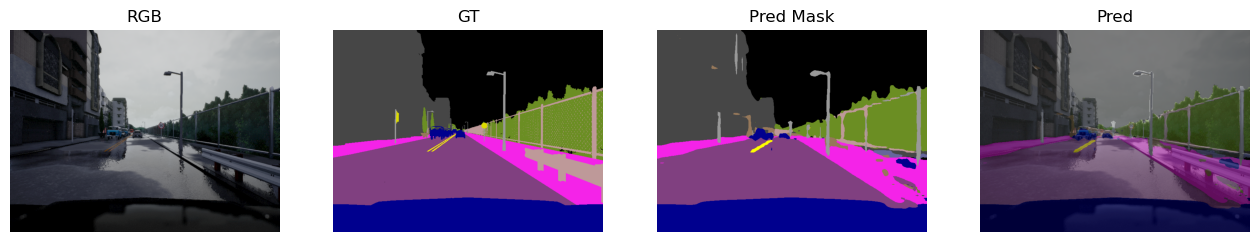

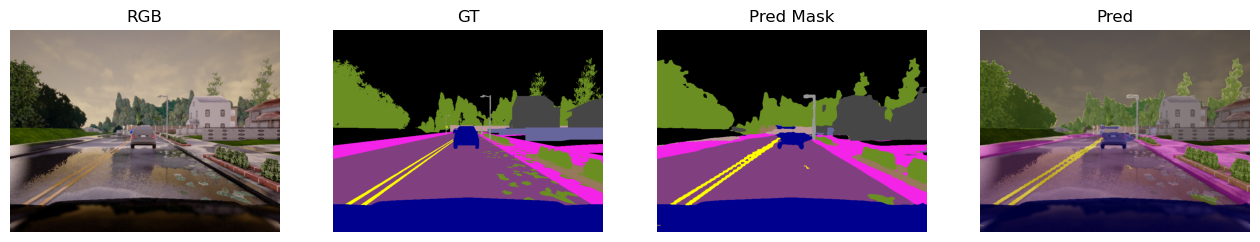

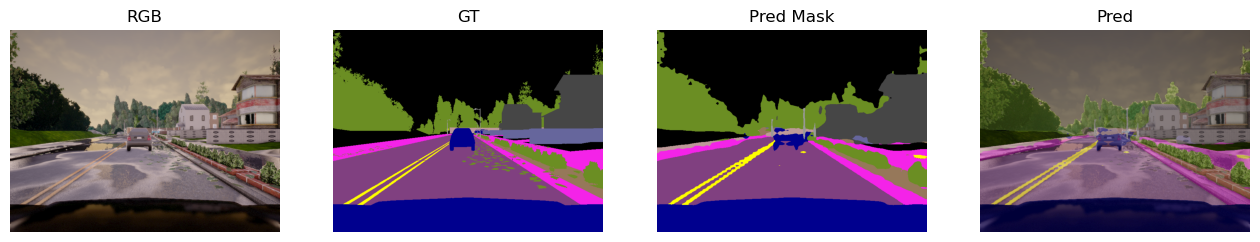

In [30]:
# idx -> acc 매핑 dict 만들기
acc_dict = {idx: acc for idx, acc in scores}

print("\n=== Best 3 samples ===")
for i in best_idx:
    print(f"Index {i}, accuracy={acc_dict[i]*100:.2f}%")
visualize_val_samples(model, test_dataset, indices=best_idx, device=device)

print("\n=== Worst 3 samples ===")
for i in worst_idx:
    print(f"Index {i}, accuracy={acc_dict[i]*100:.2f}%")
visualize_val_samples(model, test_dataset, indices=worst_idx, device=device)

print("\n=== Middle 3 samples ===")
for i in mid_idx:
    print(f"Index {i}, accuracy={acc_dict[i]*100:.2f}%")
visualize_val_samples(model, test_dataset, indices=mid_idx, device=device)
